In [ ]:
# ==========================================
# BASELINE MODEL: STANDARD UNTUNED LSTM
# Hyperparameters: manually guessed (64 neurons, lr=0.001)
# Purpose: Prove ARO optimization adds measurable value
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# ── STEP 1: MOUNT GOOGLE DRIVE ────────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')

# ── STEP 2: AUTO-FIND THE FILE ON YOUR DRIVE ──────────────────────────────────
import os

search_root = '/content/drive/MyDrive'
filename    = 'HF_DATASET.csv'
csv_file_path = None

for root, dirs, files in os.walk(search_root):
    for f in files:
        if f == filename:
            csv_file_path = os.path.join(root, f)
            break
    if csv_file_path:
        break

if csv_file_path is None:
    raise FileNotFoundError(
        f"'{filename}' was not found anywhere in your Google Drive. "
        f"Please upload it to Drive and re-run."
    )

print(f"File found at: {csv_file_path}")

# ── STEP 3: LOAD THE CSV ──────────────────────────────────────────────────────
# HF_DATASET.csv has NO header row — column names assigned manually below
df_raw = pd.read_csv(csv_file_path, header=None)

print(f"CSV loaded successfully!")
print(f"Shape: {df_raw.shape}")
display(df_raw.head())

# ── STEP 4: EXTRACT HDFC AND ICICI DATA ───────────────────────────────────────
df_hdfc = df_raw.iloc[:, 0:5].copy()
df_hdfc.columns = ['Date', 'Close', 'Volume', 'High', 'Low']

df_icici = df_raw.iloc[:, 6:11].copy()
df_icici.columns = ['Date', 'Close', 'Volume', 'High', 'Low']

# ── STEP 5: CLEAN AND INDEX BOTH DATAFRAMES ───────────────────────────────────
for df in [df_hdfc, df_icici]:
    df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
    for col in ['Close', 'Volume', 'High', 'Low']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df.dropna(inplace=True)
    df.set_index('Date', inplace=True)
    df.sort_index(inplace=True)

print(f"HDFC rows after cleaning  : {len(df_hdfc)}")
print(f"ICICI rows after cleaning : {len(df_icici)}")

# ── STEP 6: MERGE AND CALCULATE SPREAD AND Z-SCORE ───────────────────────────
data = pd.merge(
    df_hdfc, df_icici,
    left_index=True, right_index=True,
    suffixes=('_HDFC', '_ICICI')
)

data['Log_HDFC']  = np.log(data['Close_HDFC'])
data['Log_ICICI'] = np.log(data['Close_ICICI'])
data['Spread']    = data['Log_HDFC'] - data['Log_ICICI']

window = 30
data['Z_Score'] = (
    data['Spread'] - data['Spread'].rolling(window).mean()
) / data['Spread'].rolling(window).std()

data.dropna(inplace=True)

print(f"\nFinal combined rows after Z-Score calculation: {len(data)}")
display(data.head())
display(data.tail())

Mounted at /content/drive
File found at: /content/drive/MyDrive/Minor_project_dataset/HF_DATASET.csv
CSV loaded successfully!
Shape: (3988, 11)


,0,1,2,3,4,5,6,7,8,9,10
0,04-01-2010,85.29,6100980,86.43,84.63,NaN,04-01-2010,159.95,9162186,160.91,159.09
1,05-01-2010,85.36,16773200,86.25,85.25,NaN,05-01-2010,161.46,14659997,163.59,160.27
2,06-01-2010,85.42,13279680,86.00,84.41,NaN,06-01-2010,162.70,20410055,164.97,161.84
3,07-01-2010,85.64,12247960,88.42,85.08,NaN,07-01-2010,161.16,10852287,163.05,159.36
4,08-01-2010,85.75,14171800,86.17,85.05,NaN,08-01-2010,158.90,20580934,161.82,158.36


HDFC rows after cleaning  : 3988
ICICI rows after cleaning : 3988

Final combined rows after Z-Score calculation: 3959


,Close_HDFC,Volume_HDFC,High_HDFC,Low_HDFC,Close_ICICI,Volume_ICICI,High_ICICI,Low_ICICI,Log_HDFC,Log_ICICI,Spread,Z_Score
Date,,,,,,,,,,,,
2010-02-15,80.69,9604980,80.99,79.13,148.61,10649243,151.27,147.73,4.390615,5.001325,-0.610711,0.005770
2010-02-16,80.32,14349700,81.14,79.50,151.35,11282937,152.33,148.55,4.386019,5.019595,-0.633576,-1.090404
2010-02-17,82.80,24796680,83.05,80.75,152.90,28238436,154.13,151.02,4.416428,5.029784,-0.613356,-0.157511
2010-02-18,84.19,20008840,84.50,82.54,152.74,25365791,155.09,151.70,4.433076,5.028737,-0.595661,0.671783
2010-02-19,84.70,14691980,85.00,82.81,151.55,18276038,152.18,148.56,4.439116,5.020916,-0.581800,1.301525


,Close_HDFC,Volume_HDFC,High_HDFC,Low_HDFC,Close_ICICI,Volume_ICICI,High_ICICI,Low_ICICI,Log_HDFC,Log_ICICI,Spread,Z_Score
Date,,,,,,,,,,,,
2026-01-21,920.35,32766854,932.15,915.50,1349.0,21766068,1371.5,1339.5,6.824754,7.207119,-0.382365,-0.749889
2026-01-22,918.70,44444755,928.30,913.20,1345.5,17179765,1358.0,1338.0,6.822960,7.204521,-0.381561,-0.687600
2026-01-23,916.10,30985247,926.10,909.25,1343.4,14056524,1355.2,1335.7,6.820126,7.202959,-0.382833,-0.669527
2026-01-27,926.40,44753093,931.20,905.00,1361.4,25263634,1369.1,1328.6,6.831306,7.216269,-0.384963,-0.665165
2026-01-28,930.75,29806209,941.45,928.40,1367.0,10813507,1380.4,1362.6,6.835991,7.220374,-0.384383,-0.605202


In [ ]:
# ==========================================
# SAME SPLIT AND SCALER AS ARO MODEL
# Critical: identical split prevents data leakage bias
# ==========================================

split_date = '2023-01-01'
train_data = data[data.index < split_date].copy()
test_data  = data[data.index >= split_date].copy()

print(f"Training rows : {len(train_data)}")
print(f"Testing rows  : {len(test_data)}")

# Fit scaler ONLY on train — same rule as ARO model
scaler = MinMaxScaler(feature_range=(0, 1))
train_z = train_data['Z_Score'].values.reshape(-1, 1)
test_z  = test_data['Z_Score'].values.reshape(-1, 1)

scaled_train = scaler.fit_transform(train_z)
scaled_test  = scaler.transform(test_z)

Training rows : 3197
Testing rows  : 762


In [ ]:
# ==========================================
# SAME 60-DAY LOOKBACK AS ARO MODEL
# Both models see identical input sequences
# ==========================================

def create_sequences(dataset, lookback=60):
    X, y = [], []
    for i in range(lookback, len(dataset)):
        X.append(dataset[i-lookback:i, 0])
        y.append(dataset[i, 0])
    return np.array(X), np.array(y)

LOOKBACK = 60
X_train, y_train = create_sequences(scaled_train, LOOKBACK)
X_test,  y_test  = create_sequences(scaled_test,  LOOKBACK)

X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test  = X_test.reshape((X_test.shape[0],  X_test.shape[1],  1))

print(f"X_train shape: {X_train.shape}")
print(f"X_test  shape: {X_test.shape}")

X_train shape: (3137, 60, 1)
X_test  shape: (702, 60, 1)


In [ ]:
# ==========================================
# BASELINE ARCHITECTURE: HUMAN-GUESSED VALUES
# 64 neurons and lr=0.001 are textbook defaults
# No optimization — this is the "before ARO" model
# ==========================================

BASELINE_NEURONS = 64
BASELINE_LR      = 0.001

baseline_model = Sequential()
baseline_model.add(LSTM(units=BASELINE_NEURONS, return_sequences=False, input_shape=(60, 1)))
baseline_model.add(Dropout(0.2))          # Same dropout as ARO model — isolates only hyperparams
baseline_model.add(Dense(units=1))

baseline_model.compile(
    optimizer=Adam(learning_rate=BASELINE_LR),
    loss='mean_squared_error'
)

baseline_model.summary()
print(f"\nBaseline config → Neurons: {BASELINE_NEURONS}, LR: {BASELINE_LR}")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)


Baseline config → Neurons: 64, LR: 0.001


Epoch 1/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 0.0339 - val_loss: 0.0176
Epoch 2/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0162 - val_loss: 0.0143
Epoch 3/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - loss: 0.0146 - val_loss: 0.0126
Epoch 4/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - loss: 0.0125 - val_loss: 0.0115
Epoch 5/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0119 - val_loss: 0.0109
Epoch 6/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.0116 - val_loss: 0.0101
Epoch 7/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0108 - val_loss: 0.0096
Epoch 8/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - loss: 0.0104 - val_loss: 0.0091
Epoch 9/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.0101 - val_loss: 0.0088
Epoch 10/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 0.0095 - val_loss: 0.0086
Epoch 11/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 0.0092 - val_loss: 0.0081
Epoch 12/50
99/99 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.0

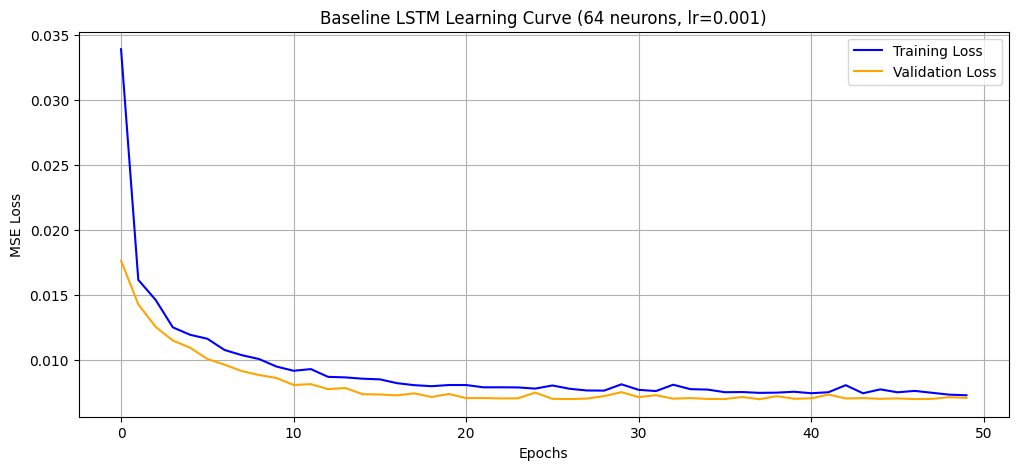

In [ ]:
# ==========================================
# TRAIN FOR 50 EPOCHS — SAME AS ARO MODEL
# Identical epochs ensure a fair wall-clock comparison
# ==========================================

baseline_history = baseline_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

# Learning curve
plt.figure(figsize=(12, 5))
plt.plot(baseline_history.history['loss'],     label='Training Loss',  color='blue')
plt.plot(baseline_history.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Baseline LSTM Learning Curve (64 neurons, lr=0.001)')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)
plt.show()

# Watch for two failure signatures here:
# 1. val_loss FLAT from epoch 1  → variance squashing (predicts a flat line, 0 trades)
# 2. val_loss rises after epoch ~10 → overfitting (memorized noise, fails on test data)

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step


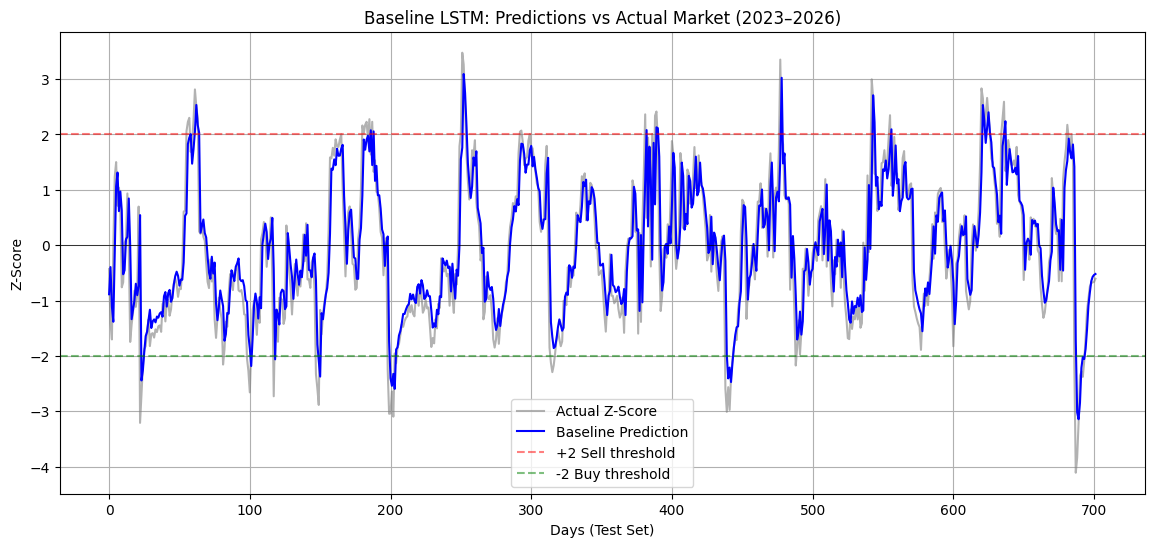

In [ ]:
# ==========================================
# GENERATE PREDICTIONS ON TEST SET (2023–2026)
# ==========================================

baseline_predictions = baseline_model.predict(X_test)

# Translate back from [0,1] scale to real Z-Score values
baseline_pred_real   = scaler.inverse_transform(baseline_predictions)
baseline_actual_real = scaler.inverse_transform(y_test.reshape(-1, 1))

# Visualize predictions vs actuals
plt.figure(figsize=(14, 6))
plt.plot(baseline_actual_real, label='Actual Z-Score',       color='grey',  alpha=0.6)
plt.plot(baseline_pred_real,   label='Baseline Prediction',  color='blue',  linewidth=1.5)
plt.axhline( 2.0, color='red',   linestyle='--', alpha=0.5, label='+2 Sell threshold')
plt.axhline(-2.0, color='green', linestyle='--', alpha=0.5, label='-2 Buy threshold')
plt.axhline( 0,   color='black', linewidth=0.5)
plt.title('Baseline LSTM: Predictions vs Actual Market (2023–2026)')
plt.xlabel('Days (Test Set)')
plt.ylabel('Z-Score')
plt.legend()
plt.grid(True)
plt.show()


BASELINE RESULTS
Initial Capital : ₹100,000
Final Capital   : ₹135,925
Total Return    : 35.93%


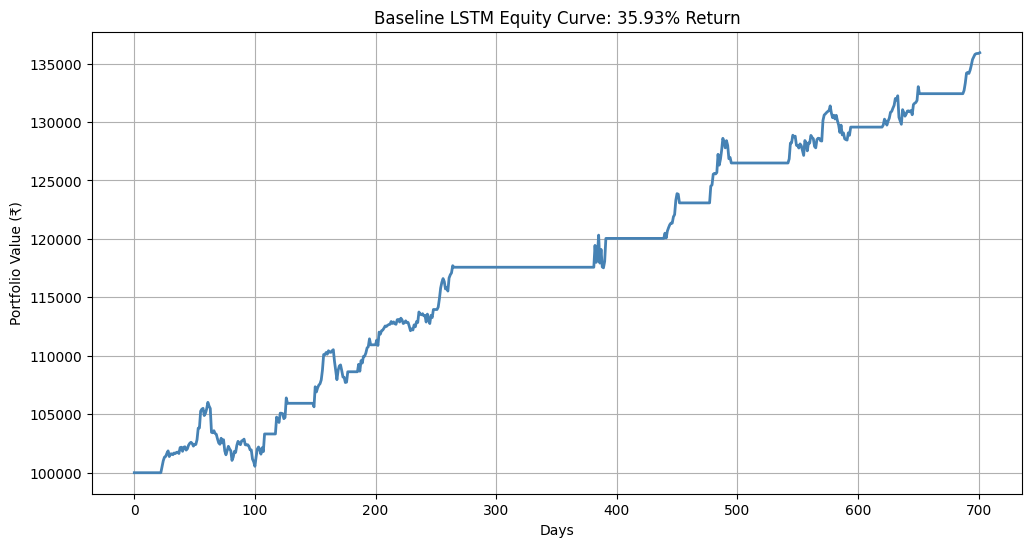

In [ ]:
# ==========================================
# IDENTICAL BACKTEST LOGIC AS ARO MODEL
# Same thresholds, same capital, same P&L formula
# ==========================================

ENTRY_THRESHOLD  = 2.0
initial_capital  = 100000
capital          = initial_capital
position         = 0
baseline_equity  = []

for i in range(len(baseline_pred_real)):
    z = baseline_pred_real[i][0]

    if z > ENTRY_THRESHOLD and position == 0:
        position = -1
    elif z < -ENTRY_THRESHOLD and position == 0:
        position = 1
    elif abs(z) < 0.1 and position != 0:
        position = 0

    if i > 0:
        z_change       = baseline_actual_real[i][0] - baseline_actual_real[i-1][0]
        daily_profit   = position * z_change * 1000
        capital       += daily_profit

    baseline_equity.append(capital)

baseline_return = ((capital - initial_capital) / initial_capital) * 100

print(f"=================================")
print(f"BASELINE RESULTS")
print(f"Initial Capital : ₹{initial_capital:,}")
print(f"Final Capital   : ₹{int(capital):,}")
print(f"Total Return    : {baseline_return:.2f}%")
print(f"=================================")

plt.figure(figsize=(12, 6))
plt.plot(baseline_equity, color='steelblue', linewidth=2)
plt.title(f'Baseline LSTM Equity Curve: {baseline_return:.2f}% Return')
plt.xlabel('Days')
plt.ylabel('Portfolio Value (₹)')
plt.grid(True)
plt.show()

In [ ]:
# ==========================================
# FULL METRICS — MIRRORS ARO MODEL REPORT CARD
# Every metric calculated identically for fair comparison
# ==========================================

equity_b       = np.array(baseline_equity)
daily_ret_b    = (equity_b[1:] - equity_b[:-1]) / (equity_b[:-1] + 1e-9)
excess_ret_b   = daily_ret_b - 0.0

sharpe_b       = (np.mean(excess_ret_b) / (np.std(excess_ret_b) + 1e-9)) * np.sqrt(252)

running_max_b  = np.maximum.accumulate(equity_b)
drawdown_b     = (equity_b - running_max_b) / running_max_b
max_dd_b       = drawdown_b.min() * 100

neg_ret_b      = daily_ret_b[daily_ret_b < 0]
sortino_b      = (np.mean(excess_ret_b) / (np.std(neg_ret_b) + 1e-9)) * np.sqrt(252) if len(neg_ret_b) > 0 else 0.0

cagr_b         = ((equity_b[-1] / equity_b[0]) ** (252 / len(equity_b)) - 1) * 100

y_true_b       = baseline_actual_real.flatten()
y_pred_b       = baseline_pred_real.flatten()
mse_b          = mean_squared_error(y_true_b, y_pred_b)
rmse_b         = np.sqrt(mse_b)
mae_b          = mean_absolute_error(y_true_b, y_pred_b)
r2_b           = r2_score(y_true_b, y_pred_b)

print("=============================================")
print("  BASELINE LSTM — FULL REPORT CARD")
print("=============================================")
print(f"  Net Profit    : ₹{int(equity_b[-1] - equity_b[0]):,}")
print(f"  Total Return  : {((equity_b[-1]-equity_b[0])/equity_b[0])*100:.2f}%")
print(f"  CAGR          : {cagr_b:.2f}%")
print(f"---------------------------------------------")
print(f"  Sharpe Ratio  : {sharpe_b:.4f}")
print(f"  Sortino Ratio : {sortino_b:.4f}")
print(f"  Max Drawdown  : {max_dd_b:.2f}%")
print(f"---------------------------------------------")
print(f"  MSE           : {mse_b:.5f}")
print(f"  RMSE          : {rmse_b:.5f}")
print(f"  MAE           : {mae_b:.5f}")
print(f"  R² Score      : {r2_b:.4f}")
print("=============================================")

  BASELINE LSTM — FULL REPORT CARD
  Net Profit    : ₹35,925
  Total Return  : 35.93%
  CAGR          : 11.65%
---------------------------------------------
  Sharpe Ratio  : 2.0527
  Sortino Ratio : 2.1945
  Max Drawdown  : -5.16%
---------------------------------------------
  MSE           : 0.41425
  RMSE          : 0.64362
  MAE           : 0.45246
  R² Score      : 0.7494
